# m05 - Classifying the Recommended Crop

The map the dashboard shows is a rule applied to the ten GAEZ indices: the crop with the highest index wins, unless even
the best index is below 5,000 ("Not recommended"). This notebook asks how well that *label* can be recovered from the 14
physical drivers, in two ways:

* **Direct**: classifiers trained on the label.
* **Regress, then apply the rule**: the surrogate regressors of notebook m01 predict the ten indices, then the same rule is
  applied to the predictions.

Targets: `thresh` (winner or "Not recommended") and `top` (plain argmax). Pixel-grouped CV vs random K-fold, 2 repeats.
Metrics that survive class imbalance matter here (balanced accuracy, macro-F1), because accuracy alone rewards predicting the
majority class.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df = E.load_table()
y_thr_s, y_top_s = E.crop_labels(df, "thresh"), E.crop_labels(df, "top")
# full label sets: the regress-then-rule route can predict crops that never win in the data (soybean, sugarcane)
classes_thr, classes_top = sorted(E.CROPS + ["Not recommended"]), sorted(E.CROPS)
y_thr = y_thr_s.map({c: i for i, c in enumerate(classes_thr)}).to_numpy()
y_top = y_top_s.map({c: i for i, c in enumerate(classes_top)}).to_numpy()

counts = pd.DataFrame({"thresh": y_thr_s.value_counts(), "top": y_top_s.value_counts()}).fillna(0).astype(int)
counts["pixels_where_it_wins (thresh)"] = y_thr_s.groupby(y_thr_s).apply(lambda s: df.loc[s.index, "pix"].nunique())
print("majority-class share  thresh: %.3f   top: %.3f" % (y_thr_s.value_counts(normalize=True).iloc[0], y_top_s.value_counts(normalize=True).iloc[0]))
counts.sort_values("thresh", ascending=False)

majority-class share  thresh: 0.547   top: 0.516


,thresh,top,pixels_where_it_wins (thresh)
label,,,
Not recommended,5102,0,105.0
coconut,2367,3063,42.0
oilpalm,1861,4813,45.0
coffee,3,98,2.0
cassava,0,62,NaN
cacao,0,8,NaN
maize,0,22,NaN
rice,0,47,NaN
rubber,0,1220,NaN


## 1. Direct classification

In [3]:
MODELS = ["dummy", "logreg", "knn", "et", "hgb", "xgb"]
SCHEMES = ["random", "pixel"]
clf_res, clf_oof = E.run_grid(df, {"thresh": y_thr, "top": y_top}, MODELS, SCHEMES, kind="clf", n_repeats=2, keep_oof=True)
E.save_table(clf_res, "m05_direct_raw")
t = clf_res.groupby(["target", "model", "scheme"])[["accuracy", "balanced_acc", "macro_f1"]].mean().unstack("scheme")
t.round(3)

48 tasks (6 models x 2 targets x 2 schemes x 2 repeats), 14 features


done in 19 s


accuracy        balanced_acc        macro_f1       
scheme           pixel random        pixel random    pixel random
target model                                                     
thresh dummy     0.547  0.547        0.250  0.250    0.177  0.177
       et        0.820  0.973        0.594  0.770    0.593  0.789
       hgb       0.827  0.979        0.604  0.776    0.601  0.774
       knn       0.772  0.922        0.545  0.679    0.547  0.681
       logreg    0.707  0.741        0.655  0.814    0.536  0.591
       xgb       0.830  0.958        0.599  0.712    0.601  0.714
top    dummy     0.516  0.516        0.125  0.125    0.085  0.085
       et        0.826  0.976        0.344  0.957    0.360  0.953
       hgb       0.841  0.983        0.339  0.972    0.355  0.967
       knn       0.790  0.930        0.320  0.659    0.328  0.698
       logreg    0.717  0.776        0.413  0.898    0.351  0.615
       xgb       0.833  0.974        0.320  0.848    0.333  0.888

## 2. Regress the indices, then apply the rule

In [4]:
REG_MODELS = ["hgb", "xgb"]
targets = {c: df[f"gaez_index_{c}"].to_numpy() for c in E.CROPS}
reg_res, reg_oof = E.run_grid(df, targets, REG_MODELS, SCHEMES, n_repeats=2, keep_oof=True, verbose=False)

def to_labels(P, mode):
    best = P.argmax(axis=1)
    names = np.array(E.CROPS, dtype=object)[best]
    if mode == "thresh":
        names = np.where(P.max(axis=1) < E.NOT_RECOMMENDED_THRESHOLD, "Not recommended", names)
    return names

rows = []
for m in REG_MODELS:
    for s in SCHEMES:
        for r in range(2):
            P = np.column_stack([reg_oof[(m, c, s, r)] for c in E.CROPS])
            for mode, truth_s, classes in [("thresh", y_thr_s, classes_thr), ("top", y_top_s, classes_top)]:
                pred = pd.Series(to_labels(P, mode)).map({c: i for i, c in enumerate(classes)}).to_numpy()
                truth = truth_s.map({c: i for i, c in enumerate(classes)}).to_numpy()
                rows.append({"target": mode, "model": f"{m} + rule", "scheme": s, "repeat": r, **E.classification_metrics(truth, pred)})
rule_res = pd.DataFrame(rows)
E.save_table(rule_res, "m05_regress_then_rule_raw")
both = pd.concat([clf_res.assign(route="direct"), rule_res.assign(route="regress+rule")], ignore_index=True)
board = both.groupby(["target", "scheme", "model"])[["accuracy", "balanced_acc", "macro_f1"]].mean().round(3)
E.save_table(board, "m05_leaderboard", index=True)
board.loc["thresh", "pixel"].sort_values("macro_f1", ascending=False)

D:\Softwares\Anaconda\Miniconda\envs\geoai-suitability\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
D:\Softwares\Anaconda\Miniconda\envs\geoai-suitability\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
D:\Softwares\Anaconda\Miniconda\envs\geoai-suitability\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
D:\Softwares\Anaconda\Miniconda\envs\geoai-suitability\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
D:\Softwares\Anaconda\Miniconda\envs\geoai-suitability\Lib\site-packages\sklearn\metrics\_classification.py:2939

,accuracy,balanced_acc,macro_f1
model,,,
hgb,0.827,0.604,0.601
xgb,0.830,0.599,0.601
et,0.820,0.594,0.593
knn,0.772,0.545,0.547
logreg,0.707,0.655,0.536
xgb + rule,0.790,0.551,0.452
hgb + rule,0.785,0.545,0.411
dummy,0.547,0.250,0.177


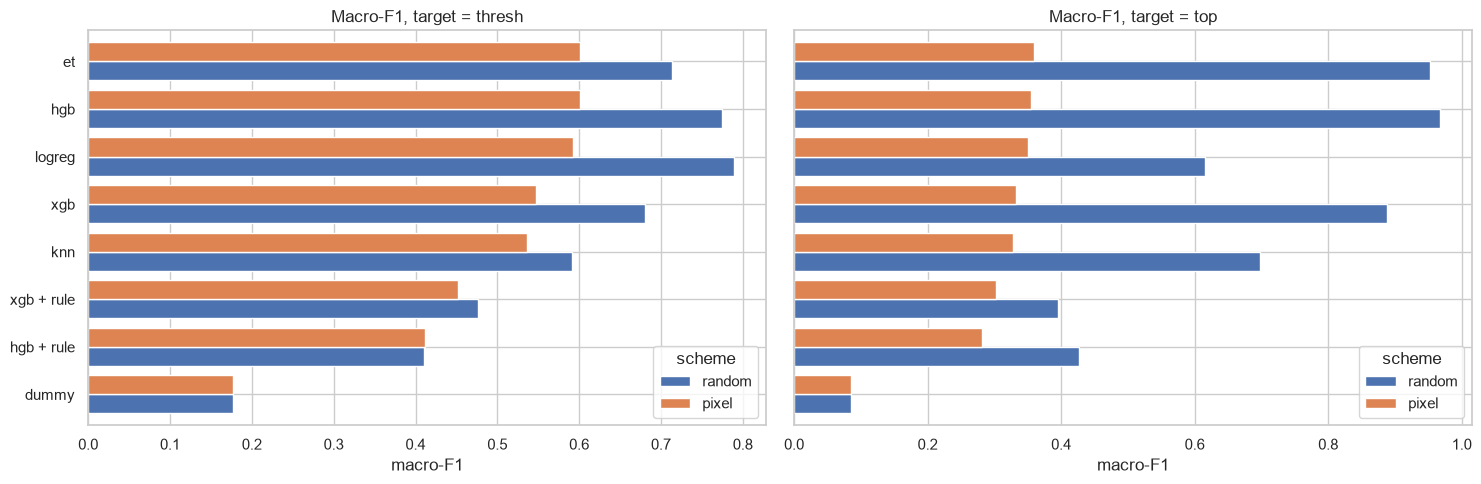

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, target in zip(axes, ["thresh", "top"]):
    sub = board.loc[target].reset_index().pivot(index="model", columns="scheme", values="macro_f1")[["random", "pixel"]]
    sub = sub.sort_values("pixel")
    sub.plot.barh(ax=ax, width=0.8)
    ax.set(title=f"Macro-F1, target = {target}", xlabel="macro-F1", ylabel="")
plt.tight_layout()
E.save_fig(fig, "m05_macro_f1")
plt.show()

## 3. Where does the best honest model go wrong?

best model for target=thresh under pixel CV: xgb


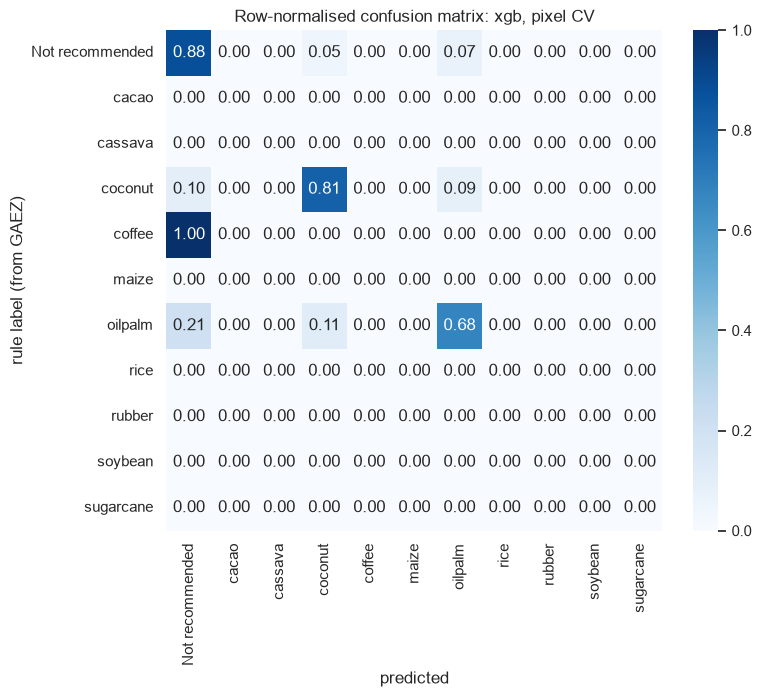

,precision,recall,f1-score,support
Not recommended,0.877,0.881,0.879,5102.000
cacao,0.000,0.000,0.000,0.000
cassava,0.000,0.000,0.000,0.000
coconut,0.810,0.812,0.811,2367.000
coffee,0.000,0.000,0.000,3.000
maize,0.000,0.000,0.000,0.000
oilpalm,0.687,0.677,0.682,1861.000
rice,0.000,0.000,0.000,0.000
rubber,0.000,0.000,0.000,0.000
soybean,0.000,0.000,0.000,0.000


In [6]:
from sklearn.metrics import classification_report, confusion_matrix

best_name = board.loc["thresh", "pixel"].drop(index=[i for i in board.loc["thresh", "pixel"].index if i.startswith("dummy")]).sort_values("macro_f1").index[-1]
print("best model for target=thresh under pixel CV:", best_name)
if best_name.endswith("+ rule"):
    m = best_name.replace(" + rule", "")
    P = np.column_stack([reg_oof[(m, c, "pixel", 0)] for c in E.CROPS])
    pred = pd.Series(to_labels(P, "thresh")).map({c: i for i, c in enumerate(classes_thr)}).to_numpy()
else:
    pred = clf_oof[(best_name, "thresh", "pixel", 0)]
cm = confusion_matrix(y_thr, pred, labels=range(len(classes_thr)), normalize="true")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes_thr, yticklabels=classes_thr, ax=ax)
ax.set(title=f"Row-normalised confusion matrix: {best_name}, pixel CV", xlabel="predicted", ylabel="rule label (from GAEZ)")
E.save_fig(fig, "m05_confusion")
plt.show()
rep = pd.DataFrame(classification_report(y_thr, pred, labels=range(len(classes_thr)), target_names=classes_thr,
                                         output_dict=True, zero_division=0)).T
rep.round(3)

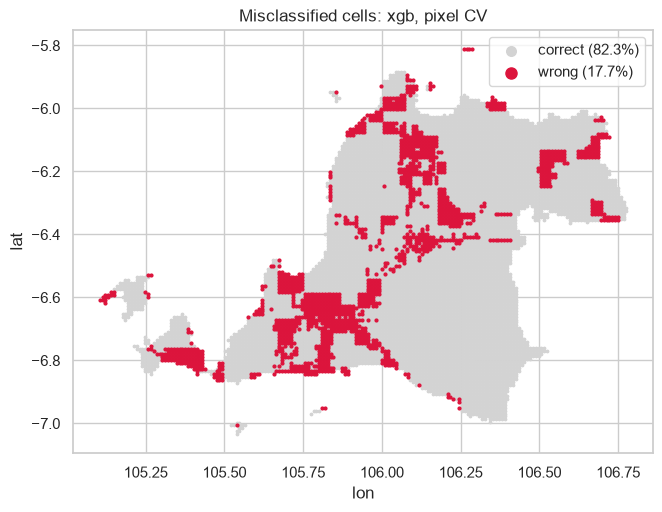

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ok = pred == y_thr
ax.scatter(df.loc[ok, "lon"], df.loc[ok, "lat"], s=3, c="lightgrey", label=f"correct ({ok.mean():.1%})")
ax.scatter(df.loc[~ok, "lon"], df.loc[~ok, "lat"], s=4, c="crimson", label=f"wrong ({(~ok).mean():.1%})")
ax.set(title=f"Misclassified cells: {best_name}, pixel CV", xlabel="lon", ylabel="lat", aspect="equal")
ax.legend(markerscale=4)
E.save_fig(fig, "m05_error_map")
plt.show()

## 4. One crop at a time: is a cell suitable (index >= 5,000)?

In [8]:
suit = {c: (df[f"gaez_index_{c}"] >= E.NOT_RECOMMENDED_THRESHOLD).astype(int).to_numpy() for c in E.CROPS}
prev = pd.Series({c: v.mean() for c, v in suit.items()}, name="prevalence").round(3)
keep_crops = [c for c in E.CROPS if 0.03 <= suit[c].mean() <= 0.97]
print("prevalence of 'suitable' per crop:\n", prev.to_string(), "\nevaluated (3-97% prevalence):", keep_crops)
bin_res, _ = E.run_grid(df, {c: suit[c] for c in keep_crops}, ["dummy", "logreg", "et", "hgb", "xgb"], SCHEMES, kind="clf", n_repeats=2, verbose=False)
E.save_table(bin_res, "m05_binary_suitability_raw")
bt = bin_res.groupby(["model", "scheme"])[["balanced_acc", "macro_f1"]].mean().unstack("scheme")
bt.round(3)

prevalence of 'suitable' per crop:
 rice         0.214
maize        0.000
cassava      0.338
soybean      0.009
oilpalm      0.424
rubber       0.000
sugarcane    0.072
coffee       0.285
cacao        0.139
coconut      0.301 
evaluated (3-97% prevalence): ['rice', 'cassava', 'oilpalm', 'sugarcane', 'coffee', 'cacao', 'coconut']


balanced_acc        macro_f1       
scheme        pixel random    pixel random
model                                     
dummy         0.500  0.500    0.425  0.425
et            0.865  0.981    0.865  0.976
hgb           0.874  0.984    0.870  0.978
logreg        0.837  0.868    0.785  0.810
xgb           0.861  0.967    0.866  0.968

In [9]:
pivot = bin_res[bin_res.scheme == "pixel"].groupby(["target", "model"])["balanced_acc"].mean().unstack("model").drop(columns="dummy")
pivot.insert(0, "prevalence", prev.reindex(pivot.index))
E.save_table(pivot.round(4), "m05_binary_by_crop_pixel", index=True)
pivot.round(3)

model,prevalence,et,hgb,logreg,xgb
target,,,,,
cacao,0.139,0.788,0.823,0.802,0.792
cassava,0.338,0.873,0.883,0.807,0.875
coconut,0.301,0.869,0.868,0.827,0.862
coffee,0.285,0.885,0.882,0.817,0.868
oilpalm,0.424,0.875,0.880,0.791,0.880
rice,0.214,0.899,0.910,0.868,0.900
sugarcane,0.072,0.869,0.874,0.943,0.849
